# 02 · Analysis: physical inactivity and diabetes across US counties

**STA 556 Final Project** · Benjamin Owusu Acquah

**Question.** Across US counties, how strongly is the prevalence of physical inactivity associated with diabetes prevalence, after accounting for obesity and smoking?

This notebook uses the analysis-ready file made by **`01_data_processing.ipynb`**. Run that notebook first.

## 1. Question and data

- **Data source:** CDC PLACES: Local Data for Better Health, County Data, 2025 release (dataset `swc5-untb`), accessed through the Socrata (SODA) API. Processing is documented in `01_data_processing.ipynb`.
- **Unit of observation:** a US county (50 states + DC).
- **Variables (age-adjusted prevalence, % of adults):**
  - `diabetes`: diagnosed diabetes, *response*
  - `lpa`: no leisure-time physical activity, *main predictor*
  - `obesity`: obesity, *control*
  - `csmoking`: current smoking, *control*
- **Main limitations:** *TODO: summarize (model-based estimates, ecological data, observational design). See Section 7.*

In [1]:
# Work from the repository root so the relative paths and `src` imports
# work whether the notebook is started from notebooks/ or from the root.
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Working directory:", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.analysis import (describe, design_matrix, ols_fit, coef_table,
                          bootstrap_coefs, percentile_ci)

PROCESSED_PATH = Path("data/processed/county_analysis.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Y = "diabetes"
X_COLS = ["lpa", "obesity", "csmoking"]
SEED = 556
N_BOOT = 2000

if not PROCESSED_PATH.exists():
    raise FileNotFoundError("Run notebooks/01_data_processing.ipynb first to create "
                            f"{PROCESSED_PATH}.")
county = pd.read_csv(PROCESSED_PATH, dtype={"locationid": str})
print("Counties:", len(county))
county.head()

Working directory: /workspaces/STA-556-Final-Project


Counties: 2956


,locationid,stateabbr,locationname,diabetes,lpa,obesity,csmoking,totalpopulation
0,01001,AL,Autauga,11.4,26.0,39.5,14.5,60342
1,01003,AL,Baldwin,10.4,23.7,35.0,13.3,253507
2,01005,AL,Barbour,16.5,34.5,47.1,20.8,24585
3,01007,AL,Bibb,13.9,31.9,43.7,19.9,21868
4,01009,AL,Blount,11.3,27.7,36.0,16.9,59816


## 2. Descriptive summaries

In [2]:
describe(county, [Y] + X_COLS)

,count,mean,std,min,25%,50%,75%,max
diabetes,2956.0,11.17,2.33,6.0,9.5,10.7,12.5,23.8
lpa,2956.0,27.02,5.39,12.2,23.4,26.5,30.5,48.9
obesity,2956.0,37.63,4.74,17.1,35.1,38.2,40.6,54.0
csmoking,2956.0,16.34,3.54,6.5,14.1,16.1,18.4,40.3


In [3]:
county[[Y] + X_COLS].corr().round(2)

,diabetes,lpa,obesity,csmoking
diabetes,1.00,0.87,0.68,0.68
lpa,0.87,1.00,0.75,0.76
obesity,0.68,0.75,1.00,0.71
csmoking,0.68,0.76,0.71,1.00


*TODO: describe typical values and spread of each measure, and which predictors are most correlated with diabetes and with each other.*

## 3. Exploratory plots

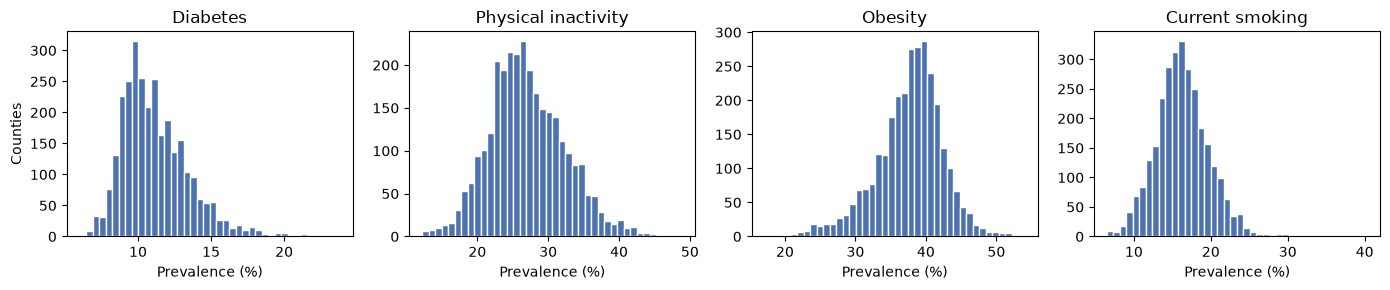

In [4]:
labels = {"diabetes": "Diabetes", "lpa": "Physical inactivity",
          "obesity": "Obesity", "csmoking": "Current smoking"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, [Y] + X_COLS):
    ax.hist(county[col], bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(labels[col])
    ax.set_xlabel("Prevalence (%)")
axes[0].set_ylabel("Counties")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_histograms.png", dpi=150)

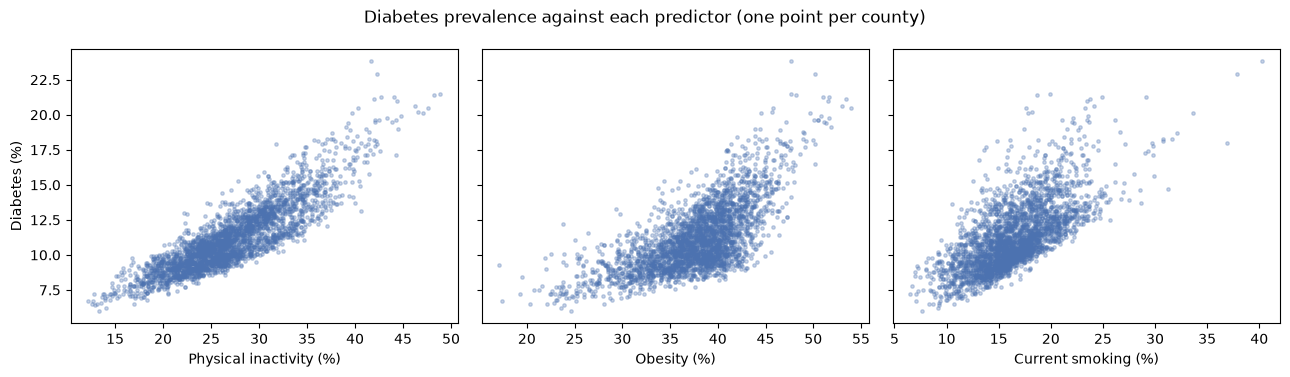

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, X_COLS):
    ax.scatter(county[col], county[Y], s=6, alpha=0.3, color="#4C72B0")
    ax.set_xlabel(f"{labels[col]} (%)")
axes[0].set_ylabel("Diabetes (%)")
fig.suptitle("Diabetes prevalence against each predictor (one point per county)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_scatter.png", dpi=150)

### Pairwise relationships and correlations (seaborn)

A pair plot shows every measure against every other, and the heatmap shows their correlations. Strong correlations among the predictors (collinearity) make their separate effects harder to estimate.

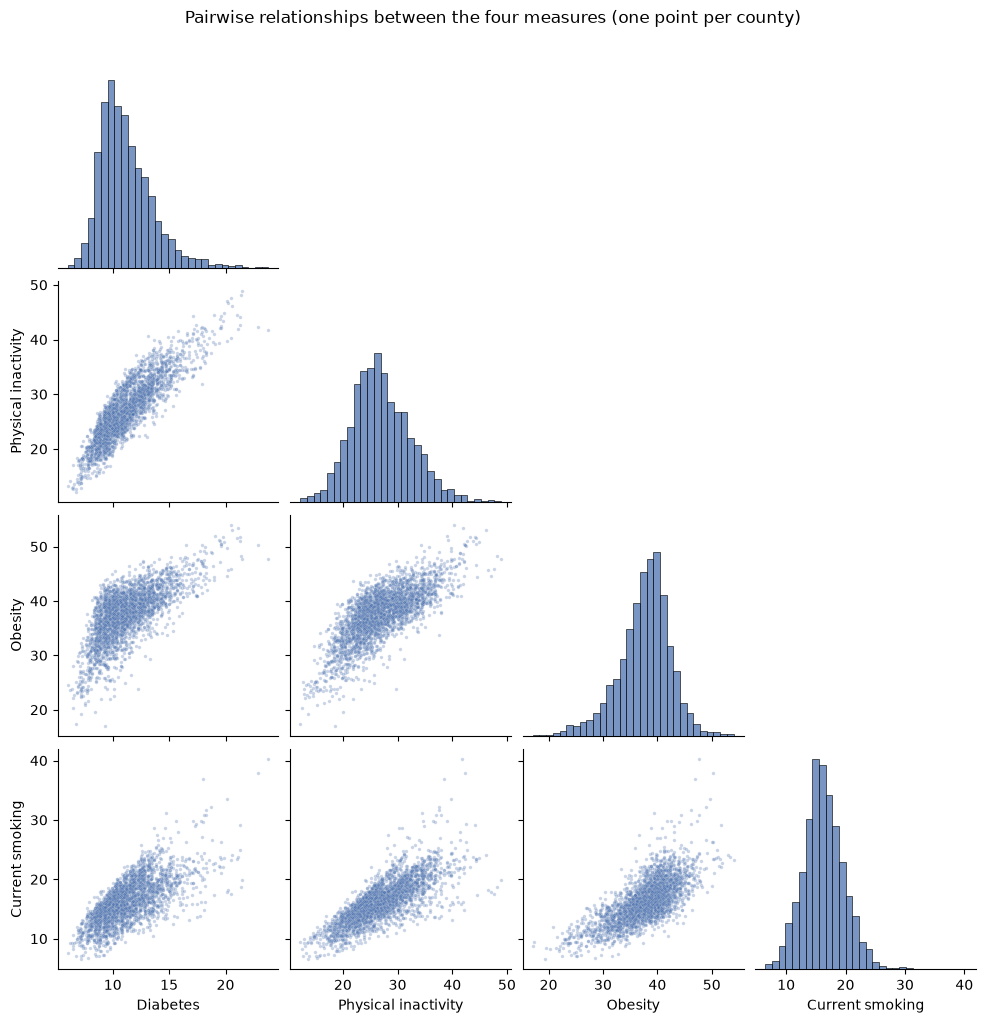

In [6]:
g = sns.pairplot(county[[Y] + X_COLS].rename(columns=labels), corner=True,
                 plot_kws={"s": 6, "alpha": 0.3, "color": "#4C72B0"},
                 diag_kws={"bins": 30, "color": "#4C72B0"})
g.figure.suptitle("Pairwise relationships between the four measures (one point per county)", y=1.02)
g.savefig(FIG_DIR / "eda_pairplot.png", dpi=150)

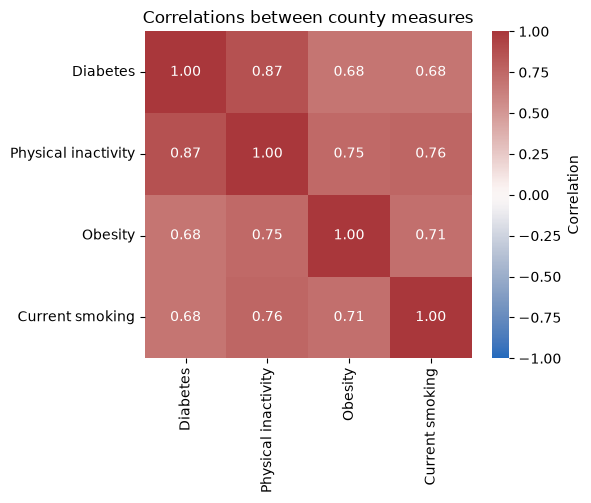

In [7]:
corr = county[[Y] + X_COLS].corr()
names = [labels[c] for c in corr.columns]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True,
            xticklabels=names, yticklabels=names, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlations between county measures")
fig.tight_layout()
fig.savefig(FIG_DIR / "corr_heatmap.png", dpi=150)

*TODO: describe what the plots show (shapes, skew, outliers, strength of each relationship).*

## 4. Least squares with NumPy

Model: $\text{diabetes}_i = \beta_0 + \beta_1\,\text{lpa}_i + \beta_2\,\text{obesity}_i + \beta_3\,\text{csmoking}_i + \varepsilon_i$

Coefficients are computed with `np.linalg.lstsq`, and standard errors with `np.linalg.solve`, never an explicit matrix inverse.

In [8]:
X = design_matrix(county, X_COLS)
y = county[Y].to_numpy()
fit = ols_fit(X, y)
print(f"n = {len(y)}, rank(X) = {fit['rank']}, condition number = {fit['cond']:.1f}, "
      f"R^2 = {fit['r2']:.3f}")
coef_table(fit, X_COLS)

n = 2956, rank(X) = 4, condition number = 405.6, R^2 = 0.765


,estimate,std_error
intercept,0.2843,0.1697
lpa,0.3508,0.0067
obesity,0.0329,0.0070
csmoking,0.0103,0.0097


### Diagnostics

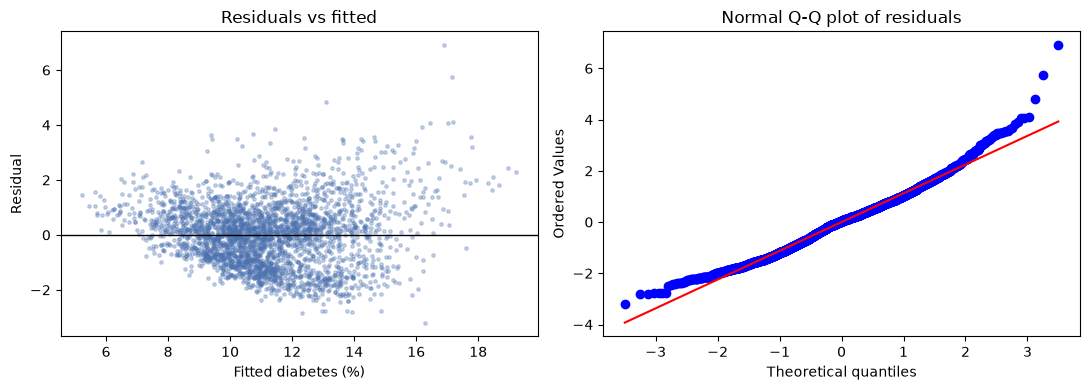

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fit["fitted"], fit["resid"], s=6, alpha=0.3, color="#4C72B0")
axes[0].axhline(0, color="black", lw=1)
axes[0].set(xlabel="Fitted diabetes (%)", ylabel="Residual", title="Residuals vs fitted")
stats.probplot(fit["resid"], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
fig.savefig(FIG_DIR / "diagnostics.png", dpi=150)

*TODO: interpret R², the condition number (are the predictors collinear?), and the residual plots (curvature, unequal spread, heavy tails). If spread is unequal, the classical SEs are unreliable, which motivates the bootstrap.*

## 5. Bootstrap uncertainty

**Mechanism.** We resample counties with replacement (a case, or pairs, bootstrap): each bootstrap sample draws $n$ rows of $(x_i, y_i)$ from the data, and we refit the least-squares model. The spread of the refitted coefficients estimates their sampling variability without assuming normal, constant-variance errors. Randomness is controlled with `np.random.default_rng(556)`.

In [10]:
rng = np.random.default_rng(SEED)
boot = bootstrap_coefs(X, y, n_boot=N_BOOT, rng=rng)
ci = percentile_ci(boot)
results = coef_table(fit, X_COLS)
results["boot_se"] = boot.std(axis=0, ddof=1).round(4)
results["ci_low"], results["ci_high"] = ci[:, 0].round(4), ci[:, 1].round(4)
results

,estimate,std_error,boot_se,ci_low,ci_high
intercept,0.2843,0.1697,0.1902,-0.1136,0.6353
lpa,0.3508,0.0067,0.0071,0.3368,0.3640
obesity,0.0329,0.0070,0.0077,0.0177,0.0480
csmoking,0.0103,0.0097,0.0151,-0.0205,0.0397


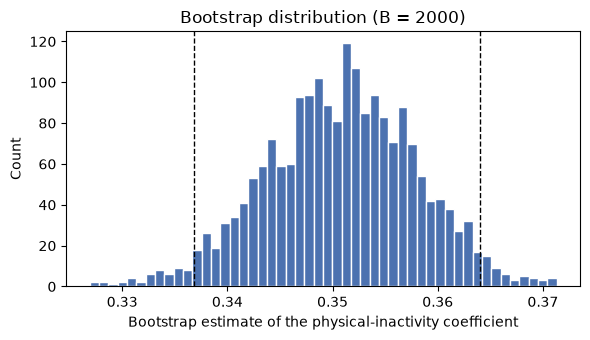

In [11]:
j = 1  # column of X for physical inactivity
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(boot[:, j], bins=50, color="#4C72B0", edgecolor="white")
for v in ci[j]:
    ax.axvline(v, color="black", ls="--", lw=1)
ax.set(xlabel="Bootstrap estimate of the physical-inactivity coefficient",
       ylabel="Count", title=f"Bootstrap distribution (B = {N_BOOT})")
fig.tight_layout()
fig.savefig(FIG_DIR / "bootstrap_lpa.png", dpi=150)

*TODO: interpret the 95% CI for the physical-inactivity coefficient in plain words (e.g., 'holding obesity and smoking fixed, counties with 1 percentage point more inactivity have about … points higher diabetes prevalence'). Compare bootstrap SEs to the classical SEs, and note that B = 2000 keeps Monte Carlo variability in the CI endpoints small.*

## 6. Communication figure

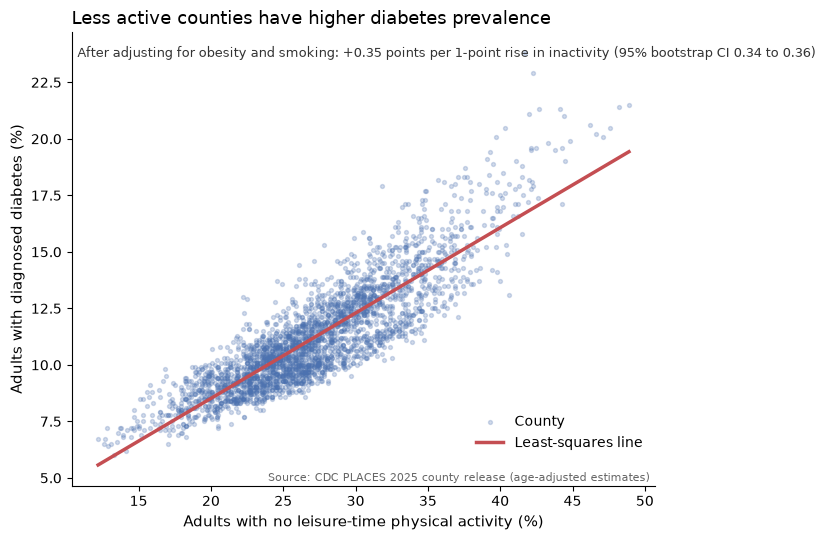

In [12]:
b_lpa, (lo, hi) = fit["beta"][1], ci[1]
slope, intercept = np.polyfit(county["lpa"], county[Y], 1)
xs = np.linspace(county["lpa"].min(), county["lpa"].max(), 100)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(county["lpa"], county[Y], s=8, alpha=0.25, color="#4C72B0", label="County")
ax.plot(xs, intercept + slope * xs, color="#C44E52", lw=2.5, label="Least-squares line")
ax.set_xlabel("Adults with no leisure-time physical activity (%)", fontsize=11)
ax.set_ylabel("Adults with diagnosed diabetes (%)", fontsize=11)
ax.set_title("Less active counties have higher diabetes prevalence", fontsize=13, loc="left")
ax.text(0.01, 0.97,
        f"After adjusting for obesity and smoking: +{b_lpa:.2f} points per 1-point rise in inactivity "
        f"(95% bootstrap CI {lo:.2f} to {hi:.2f})",
        transform=ax.transAxes, va="top", fontsize=9, color="#333333")
ax.text(0.99, 0.01, "Source: CDC PLACES 2025 county release (age-adjusted estimates)",
        transform=ax.transAxes, ha="right", fontsize=8, color="#666666")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.05), frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "communication_figure.png", dpi=200)

*Check the title against your real results and change it if the data say otherwise.*

## 7. Limitations

*TODO: write 1–2 short paragraphs. Points to cover:*
- *PLACES values are model-based small-area estimates (from BRFSS survey data and census covariates), not direct county counts; their own uncertainty is ignored here.*
- *Because the estimates are partly built from the same county demographics, associations between measures may be inflated.*
- *Ecological data: county-level associations do not describe individuals.*
- *Observational design: no causal conclusions; income, age structure, healthcare access and other confounders are omitted.*
- *Counties are not independent (neighbouring counties are similar), so even the bootstrap understates uncertainty somewhat.*

## 8. Conclusion

*TODO: answer the question in 2–3 sentences.*